 <div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <font color='green'> <b><u>КОММЕНТАРИЙ РЕВЬЮЕРА</u></b><br>
Мария, доброго дня! рад приветствовать тебя) <br />
<br />
Меня зовут Николай Шавлюго. <br />И на этом этапе твоего движения к новой профессии от меня будут комментарии по написанному коду. <br />Чтобы меньше "мусорить эфир" и чтобы максимально наглядно отделяться от основного кода, есть предложение условиться в некоторых обозначениях:<br /> <br />
<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>Всё хорошо.</p>
</div>

<div class="alert alert-warning" style="border-color: darkorange; border-radius: 5px">
    <p><u><b>⚠️ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>Обрати внимание, есть потенциал</p>
</div>

<div class="alert alert-danger" style="border-color: darkred; border-radius: 5px">
    <p><u><b>❌ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>Нужно ещё раз глянуть</p>
</div>
</font><br /><br />
<font color='green'>Моей целью является не "уличить" в не знании, а просто высказать сверху твоих знаний - свой опыт, что бы тебе использовать его для своего дальнейшего успеха) И очень здорово будет, если удастся задавать вопросы, да и вообще - всячески доставать меня, если я по каким-то причинам не приму проект:) При этом, из своего опыта скажу, хорошо и важно, когда переписка ревьюера и студента - сохраняется на следующие проекты и даже на будущую практическую деятельность.<br>
<br> Я сразу же начал общаться на ты:) но если это не очень удобно, то дай знать)) <BR> В ПУТЬ!<br></div>

<h1>Содержание<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Подготовка" data-toc-modified-id="Подготовка-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Подготовка</a></span></li><li><span><a href="#Анализ" data-toc-modified-id="Анализ-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Анализ</a></span></li><li><span><a href="#Обучение" data-toc-modified-id="Обучение-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Обучение</a></span></li><li><span><a href="#Тестирование" data-toc-modified-id="Тестирование-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Тестирование</a></span></li><li><span><a href="#Чек-лист-проверки" data-toc-modified-id="Чек-лист-проверки-5"><span class="toc-item-num">5&nbsp;&nbsp;</span>Чек-лист проверки</a></span></li></ul></div>

#  Прогнозирование заказов такси

Компания «Чётенькое такси» собрала исторические данные о заказах такси в аэропортах. Чтобы привлекать больше водителей в период пиковой нагрузки, нужно спрогнозировать количество заказов такси на следующий час. Постройте модель для такого предсказания.

Значение метрики *RMSE* на тестовой выборке должно быть не больше 48.

Вам нужно:

1. Загрузить данные и выполнить их ресемплирование по одному часу.
2. Проанализировать данные.
3. Обучить разные модели с различными гиперпараметрами. Сделать тестовую выборку размером 10% от исходных данных.
4. Проверить данные на тестовой выборке и сделать выводы.


Данные лежат в файле `taxi.csv`. Количество заказов находится в столбце `num_orders` (от англ. *number of orders*, «число заказов»).

## Подготовка

In [387]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import lightgbm
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import TimeSeriesSplit
from matplotlib.pyplot import plot

Импортируем необходимые библиотеки

In [388]:
df = pd.read_csv('/datasets/taxi.csv', index_col=[0], parse_dates=[0])
df.sort_index(inplace=True)
df.head()

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>ОК, данные на базе)</p>
</div>

In [389]:
df = df.resample('1H').sum()

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>верно!!)</p>
</div>

Ресэмплинг в час

In [390]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: H
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  4416 non-null   int64
dtypes: int64(1)
memory usage: 69.0 KB


In [391]:
print(df.isna().sum())

num_orders    0
dtype: int64


Пропусков нет, Datetime в роли индексации, датасет готов к дальнейшей работе

## Анализ

In [392]:
df_copy = df.copy()
df_copy['rolling_mean'] = df_copy.rolling(24).mean()


<AxesSubplot:xlabel='datetime'>

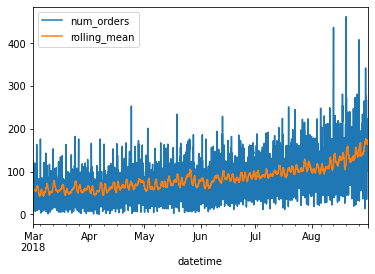

In [393]:
df_copy.plot()

По данному графику можно понять, что в целом данный сервис такси становится все более успешным с течением времени

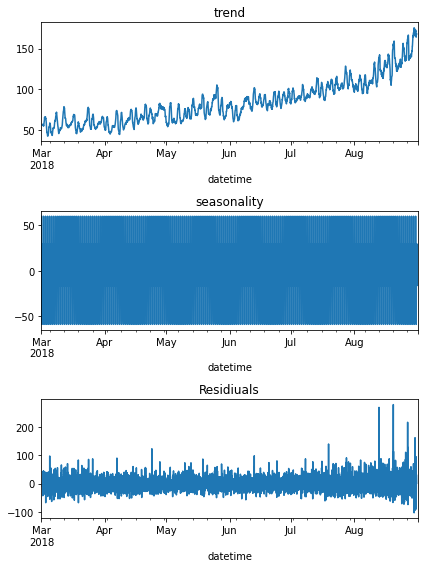

In [394]:
decomposed = seasonal_decompose(df)
plt.figure(figsize=(6,8))
plt.subplot(311)
decomposed.trend.plot(ax=plt.gca())
plt.title('trend')
plt.subplot(312)
decomposed.seasonal.plot(ax=plt.gca())
plt.title('seasonality')
plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())
plt.title('Residiuals')
plt.tight_layout()


Трендовая составляющая действительно подтверждает вышеизложенное предположение.
А вот сезоннная пока является неинформативной. Сервис популярен постоянно.

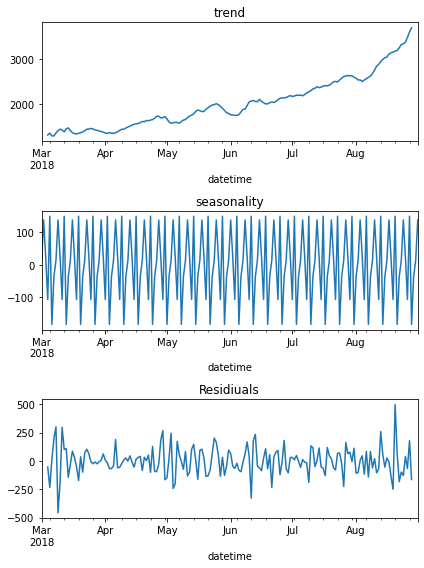

In [395]:
df_d = df.resample('1D').sum()

decomposed_d = seasonal_decompose(df_d)
plt.figure(figsize=(6,8))
plt.subplot(311)
decomposed_d.trend.plot(ax=plt.gca())
plt.title('trend')
plt.subplot(312)
decomposed_d.seasonal.plot(ax=plt.gca())
plt.title('seasonality')
plt.subplot(313)
decomposed_d.resid.plot(ax=plt.gca())
plt.title('Residiuals')
plt.tight_layout()

Востребованность такси, видимо, варьирует в зависимости от дня недели.

In [396]:
print(df.iloc[-1])

num_orders    205
Name: 2018-08-31 23:00:00, dtype: int64


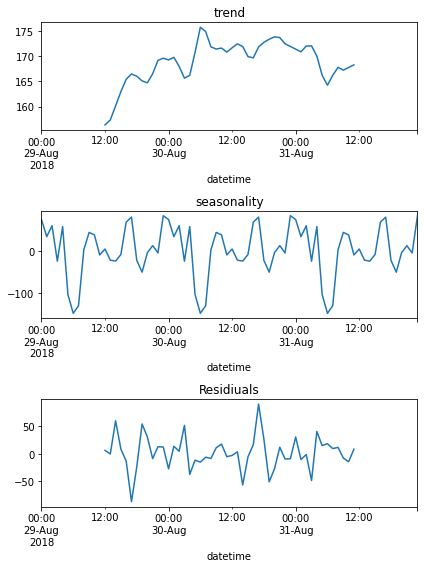

In [397]:
decomposed_sut = seasonal_decompose(df['2018-08-29': '2018-08-31'])
plt.figure(figsize=(6,8))
plt.subplot(311)
decomposed_sut.trend.plot(ax=plt.gca())
plt.title('trend')
plt.subplot(312)
decomposed_sut.seasonal.plot(ax=plt.gca())
plt.title('seasonality')
plt.subplot(313)
decomposed_sut.resid.plot(ax=plt.gca())
plt.title('Residiuals')
plt.tight_layout()

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>
Исследование - понятно.<font color='green'><br> График сезонности лучше глянуть на коротком периоде. Сделай, пожалуйста<br><font color='green'><br>
Инструмент декомпозиции в частности, а графический анализ временных рядов как в принципе - важный этап моделирования рядов.<br> Позволяет увидеть продажи визуально, а это помогает сделать предвариетльные выводы<br>
    
Хочу озвучить ещё такой момент<br>
В реальности бизнеса есть все три вида сезонности:<br>
1) дневная сезонность -  данные собраны по дням, т.е. будни и выходные имеют разные продажи<br>
2) внутрисуточная сезонность: когда продажи утром отличаются от продаж вечером <br>
3) месячная сезонность: когда продажи лета и осени - разные.<br><br>
И если строить прогноз на длительный период времени, то без учёта всех видов сезонности  - не обойтись<br>
Например: есть в данных восходящий тренд. Но вопрос такой возникает: <br>
этот подъём действительно за счёт роста компании (чаще всего тренд - это отражение роста компании) или есть ещё влияние месячной сезнности? (летом - продаж в рост, например, и именно этот момент мы наблюдаем в данных)<br>
Ответ на вопрос - не протой на имеющихся данных - у нас данных меньше года. А это означает, что месячную сезонность нам не просто вычислить адекватно - т.е. не внести в модель корректтировки месяцев(<br>
Поэтому, я бы дал такой совет:<br>
на горизонте прогнозирования - несколько часов или дней - можно предположить что у нас тренд.<br>
А если строить прогноз на несколько недель - вот тут утверждать наличие тренда надо с большой осторожностью))))<br><br>
Ну, а если вернуться к постановке задаче - построить прогноз на час (очень маленький горизонт), то двух сезонности часовой и дневной - должно хватить.
</font></p></div>

Принято, действительно нельзя в данном контексте с уверенностью говорить о восходящем тренде.

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА 2</b></u></p>
    <p>👍👍</p>
</div>

In [398]:
#decomposed_oneday = seasonal_decompose(df['2018-08-31'])
#plt.figure(figsize=(6,8))
#decomposed_oneday.seasonal.plot(ax=plt.gca())
#plt.title('seasonality')

А как можно сделать график часовой сезонности, если код выше выдает следующую ошибку?

x must have 2 complete cycles requires 48 observations. x only has 24 observation(s)

сама ошибка то мне понятна, но я может задачу нормально не понимаю

Посмотрим на востребованность такси в зависимости от времени суток за период последних трех дней. Наименее популярен сервис ранним утром.

In [399]:
def make_features(data, max_lag, rolling_mean_size):
    data['dayofweek'] = data.index.dayofweek
    data['hour'] = data.index.hour
    
    for lag in range(1, max_lag + 1):
        data['lag_{}'.format(lag)] = data['num_orders'].shift(lag)

    data['rolling_mean'] = data['num_orders'].shift().rolling(rolling_mean_size).mean()

make_features(df, 8, 8)
print(df.head())

                     num_orders  dayofweek  hour  lag_1  lag_2  lag_3  lag_4  \
datetime                                                                       
2018-03-01 00:00:00         124          3     0    NaN    NaN    NaN    NaN   
2018-03-01 01:00:00          85          3     1  124.0    NaN    NaN    NaN   
2018-03-01 02:00:00          71          3     2   85.0  124.0    NaN    NaN   
2018-03-01 03:00:00          66          3     3   71.0   85.0  124.0    NaN   
2018-03-01 04:00:00          43          3     4   66.0   71.0   85.0  124.0   

                     lag_5  lag_6  lag_7  lag_8  rolling_mean  
datetime                                                       
2018-03-01 00:00:00    NaN    NaN    NaN    NaN           NaN  
2018-03-01 01:00:00    NaN    NaN    NaN    NaN           NaN  
2018-03-01 02:00:00    NaN    NaN    NaN    NaN           NaN  
2018-03-01 03:00:00    NaN    NaN    NaN    NaN           NaN  
2018-03-01 04:00:00    NaN    NaN    NaN    NaN        

<div class="alert alert-danger" style="border-color: darkred; border-radius: 5px">
    <p><u><b>❌ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
На мой взгляд: не все факторы подходят, чисто логически. Выскажу свою позицию:<br><br>

1) Фактор год: НЕТ, однозначно не подходит. У нас данных меньше года. Поэтому будет просто константа ХОРОШО, ЧТО НЕ ИСПОЛЬЗУЕШЬ.<br>
2) Фактор месяц: НЕТ, аналогично году, у нас в истории всего один март, май.... Да и горизоно прогноза - часы. Поэтому сезонность времени года будет просто в тренде уже заложена.<br>
3) Фактор день: НЕТ, также не подходит, будет просто последовательность чисел<br>
4) Фактор день недели: ДА, т.к. у нас есть недельная сезонность<br>
5) Фактор час: ДА, т.к. есть часовая (суточная) сезонность.<br>
6) Факто lag: ДА, это параметр авторегрессии - учёт влияния вчерашних событий на сегодняшние.<br>
7) Фактор rolling: ДА, это аналог тренда. Чем больше окно сглаживания, тем ровнее линия тренда <br>

Как ты думаешь?</div>

Действительно так, внесла изменения.

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА 2</b></u></p>
    <p>хорошо</p>
</div>

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p> Сразу пару строк о факторе месяц:<br>
Если нам брать горизонт прогноза месяц или два , то фактор месяц - очень важне  это факт. А если брать горизонт прогноза несколько часов, то фактор времени года - на таком отрезке времени и не заметен. К тому же, он уже присутствует в тренде (скользящем среднем). Т.е. его участие локально как бы и есть.<br>

То, что сейчас месяц может увеличивать точность - это случайно. Он ведь представлен как числа от 1 до 8 и ещё есть тренд, как раз. Т.е. произошло наложение тренда и номера месяца. А вот если продажи буду уходить вниз (или перестанут расти), а мы будем продолжать пользовться моделью, то модель будет предсказывать рост на сентябрь (цифра 9), на октябпрь (цифра 10)... т.е. чиссто числовая тенденция)<br>
    
Поэтому, рекомендация для будущих проетов на эту тему:<br>
Учитывать горизонт прогноза: если задача стоит среднесрочного и долгосрочного прогноза, то месяц нам в помощь (при этом данных должно быть не меннее 2-х / 3-х лет). Если задача краткосрочного прогнозирования - месяц не надо использовать, он уже в тренде заложен.</div>

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>Пару строк по фактору лаг и скользящее среднее:<br>
Lag: его называют ещё параметром авторегрессии. На бытовом уровне его можно понять так: допустим вчера мы собрались с друзьями и не много закусили.... повлияет ли это на сегодняшний настрой на жизнь? Скорее да)))) Так вот с авторегрессией также. Допустим lag=1 - учитывает (для удобства будем считать, что продажи собраны по дням) как вчерашние продажи - вчерашние события - воалияли на сегоняшние.Lag=2: учитывает как позавчерашние продажи влияютна сегодняшние.....<br>
    
По скользящему среднего:<br>
Предположим rolling=10 - скользящее среднее. По сути, ищем среднее по 10 точкам, потом следующие 10 точек, и т.д. - это некое подобие тренда будет - средней линии. Т.е. - сглаживание колебаний/выбросов. Это легко увидеть на пределе: допустим длина ряда 100 дней. rolling(100) - это просто одно число - среднее всего ряда. <br>
    
Поэтому, если выставить сезонности - hour и деньНедели, то дополнительные факторы могут быть такие: лаг =1 (максимум 2), а скользящее среднее = 24 (среднее за сутки). Т.е. начинать с этого. В итоге модель будет приемлемая по точности и не много факторов.. а это значит и для бизнеса будет легче доносить решение)</div>

Создадим в датасете новые признаки, необходимые для дальнейшего исследования и обучения и предсказания моделей.

<AxesSubplot:xlabel='hour'>

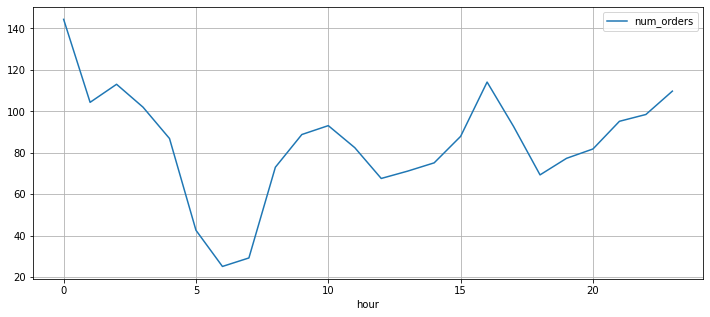

In [400]:
df.pivot_table(index='hour', values='num_orders').plot(grid=True, figsize=(12, 5))

Самый большой пик приходится на 12 часов ночи. Также важны следующие точки: 2 часа ночи, 10 часов утра, 16 часов вечера. Наиболее востребованным сервис такси по усредненным историческим данным в следующие временные периоды: с 20.00 по 04.00, с 8.00 по 11.00, с 14.00 по 17.30.

## Обучение

In [401]:
train, test = train_test_split(df, shuffle=False, test_size=0.2)
train = train.dropna()

features_train = train.drop(['num_orders'], axis=1)
target_train = train['num_orders']
features_test = test.drop(['num_orders'], axis=1)
target_test = test['num_orders']

In [402]:
model = LinearRegression()

In [403]:
%%time
model.fit(features_train, target_train)

CPU times: user 3.49 ms, sys: 3.9 ms, total: 7.39 ms
Wall time: 6.19 ms


LinearRegression()

In [404]:
linear_fit_time = 3.16 / 1000

In [405]:
%%time
predictions_train = model.predict(features_train)
#predictions_test = model.predict(features_test)

CPU times: user 19 ms, sys: 12.6 ms, total: 31.6 ms
Wall time: 57.2 ms


In [406]:
linear_predict_time = 11.1 / 1000

In [407]:
rmse_train = mean_squared_error(target_train, predictions_train) ** 0.5
print(rmse_train)

29.57913617682088


In [408]:
print(f'''Значение метрики RMSE на обучающей выборке для LinearRegression''', cross_val_score(model, features_train, target_train, 
                         cv = TimeSeriesSplit(n_splits=8), 
                         n_jobs = -1, 
                         scoring = 'neg_root_mean_squared_error').mean())

Значение метрики RMSE на обучающей выборке для LinearRegression -30.3610729669863


In [409]:
linear_rmse_value = 30.3610729669863

<div class="alert alert-warning" style="border-color: darkorange; border-radius: 5px">
    <p><u><b>⚠️ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>Сообщество рекомендует так: сначала все модели изучаем на трайн-периоде. Потом вводим результирующую таблицу и выбираем лучшую. И ТОЛЬКО её и тестируем на тесте. Давай и здесь так сделаем, это будет правильнее. А линейную регрессию лучше через кросс-валидацию сделать. вот ниже пример:</p>
</div>

Линейная регрессия обучена.

In [410]:

train_d = lightgbm.Dataset(features_train, label=target_train)

In [411]:
test_d = lightgbm.Dataset(features_test, label=target_test)
parameters = {'metric': 'rmse',  'is_unbalance': 'true', 'boosting': 
              'gbdt', 'num_leaves': 31, 'feature_fraction': 0.5, 
              'bagging_fraction': 0.5,  'bagging_freq': 20,  
              'learning_rate': 0.05}

In [412]:
%%time
LightGBM_model = lightgbm.train(parameters, train_set=train_d, valid_sets=test_d, num_boost_round=100)

[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.221783 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1694
[LightGBM] [Info] Number of data points in the train set: 3524, number of used features: 11
[LightGBM] [Info] Start training from score 74.356413
[1]	valid_0's rmse: 72.9431
[2]	valid_0's rmse: 71.6731
[3]	valid_0's rmse: 71.5697
[4]	valid_0's rmse: 70.4086
[5]	valid_0's rmse: 69.3307
[6]	valid_0's rmse: 68.2067
[7]	valid_0's rmse: 68.136
[8]	valid_0's rmse: 67.1419
[9]	valid_0's rmse: 66.1022
[10]	valid_0's rmse: 65.2049
[11]	valid_0's rmse: 64.2132
[12]	valid_0's rmse: 63.4927
[13]	valid_0's rmse: 62.7411
[14]	valid_0's rmse: 62.0161
[15]	valid_0's rmse: 61.2223
[16]	valid_0's rmse: 60.6186
[17]	valid_0's rmse: 59.9731
[18]	valid_0's rmse: 59.3253
[19]	valid_0's rmse: 58.8925
[20]	valid_0's rmse: 58.3138
[21]	valid_0's rmse: 57.7025
[22]	valid_0's rmse: 57.0604
[23]	valid_0's rmse: 56.738

In [413]:
light_fit_time = 2*60 + 23

<div class="alert alert-warning" style="border-color: darkorange; border-radius: 5px">
    <p><u><b>⚠️ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
    <p>Тут возникает правомерный вопрос: а откуда параметры модели?) Лучше оставлять сам расчёт-подбор их. А то такой результат противоречит нашей профессии: у нас нет аргументации, почему именно такая моедль. Пртосто взяли числос потолка?:)</p>
</div>

In [414]:
%%time
LightGBM_predictions = LightGBM_model.predict(features_train)

CPU times: user 22 ms, sys: 0 ns, total: 22 ms
Wall time: 6.99 ms


In [415]:
light_predict_time = 92.5/1000

In [416]:
LightGBM_rmse_value = mean_squared_error(target_train, LightGBM_predictions) ** 0.5
print(LightGBM_rmse_value)

17.883831552328484


LightJBM обучена.

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
вот тут хорошо бы результирующую табличку с результатами моделей - будет всем видно кто и почему лучший. А дальше ТОЛЬКО лучшую модель тестируем!!!!!

In [417]:
results = pd.DataFrame({'model': ['LinearRegression', 'LightGBM'], 'fit time': [linear_fit_time, light_fit_time], 'predict time': [linear_predict_time, light_predict_time], 'rmse':[linear_rmse_value, LightGBM_rmse_value]})
display(results)

,model,fit time,predict time,rmse
0,LinearRegression,0.00316,0.0111,30.361073
1,LightGBM,143.00000,0.0925,17.883832


## Тестирование

In [418]:
rmse_test = mean_squared_error(target_test, predictions_test) ** 0.5
print(rmse_test)

47.370045712556006


Результат линеной регрессии по метрике rmse приемлемый, но не лучший

In [419]:
LightGBM_predictions = LightGBM_model.predict(features_test)
LightGBM_rmse_value = mean_squared_error(target_test, LightGBM_predictions) ** 0.5
print(LightGBM_rmse_value)

45.6040210750171


Результат модели градиентного бустинга значительно лучше.

# Выводы

1. В динамике вызовов такси данного сервиса довольно ярко выражены как тренд, так и сезонность.

2. Наиболее востребованным сервис такси по усредненным историческим данным в следующие временные периоды: с 20.00 по 04.00, с 8.00 по 11.00, с 14.00 по 17.30.
    
3. Как модель линейной регрессии, так и модель градиентного бустинга дают предсказания, приемлемые согласно метрике rmse

4. LightJBM справляется с данной задачей значительно лучше и может быть порекомендована заказчику.

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА</b></u></p>
Ок, Мария, с модельной частью тебе удалось справиться хорошо!<br>
Видно, что этот скил уже достаточно сильный.<br>
Метрика - ОК. Но не понятно, если честно, а хороша ли эта модель в плане предсказания? Для этого лучше построить дополнительно график (чуть ниженаписал об этом).<br>
    
И если сутейно рассуждать, то временные ряды стоят особняком во всём курсе, я бы сказал. Тут чуть иная модельная философия. Имменно поэтому позволял себе оставлять большие рассуждения, чтобы как-то раскрыть её особенности.<br>
<font color='red'>         
Оставил несколько важных комментариев в тексте (жёлтые - тоже важны). Готов буду ответить на твои вопросы!<br>
   
Также попрошу вот что:<br>
Выведи, пожалуйста графики факт/предсказанное на одном рисунке (обычный линейный график). Чтобы увидеть где основные не "попадалки" модели. Это один из важнейших инструментов анализа результатов моделирования временных рядов.<br>
Лучше выбрать масштаб, скажем, несколько дней, чтобы увиеть можо было и сравнить каждый час.<br>    
<font color='green'>
Спасибо)<BR>
БУДУ ЖДАТЬ КОММЕНТАРИЕВ</div> 

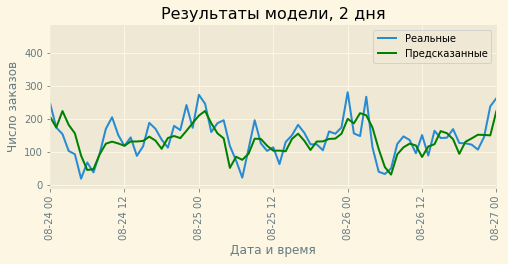

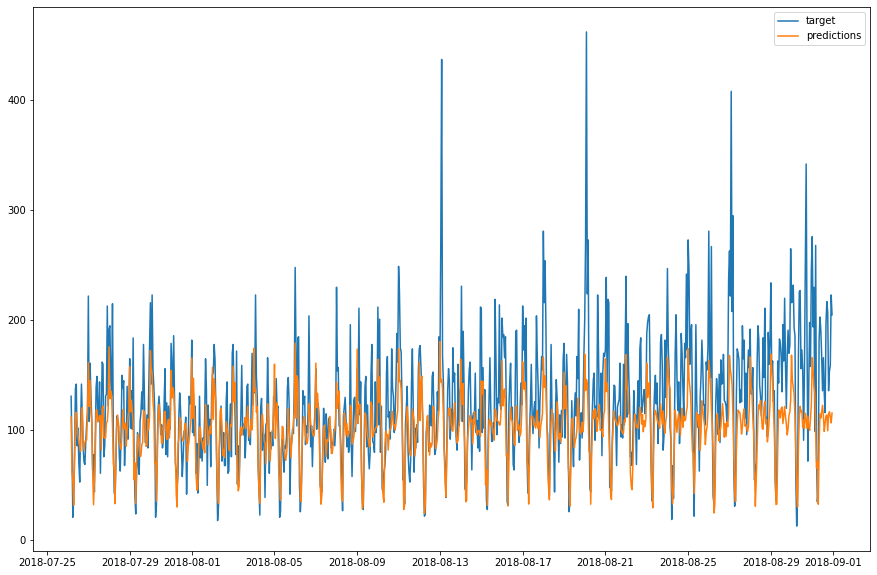

In [429]:
#plt.plot(features_test.index, target_test)
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(features_test.index, target_test, label='target')
ax.plot(features_test.index, LightGBM_predictions, label='predictions')
ax.legend();

In [432]:
LightGBM_predictions_df = pd.DataFrame(LightGBM_predictions, index=features_test.index)

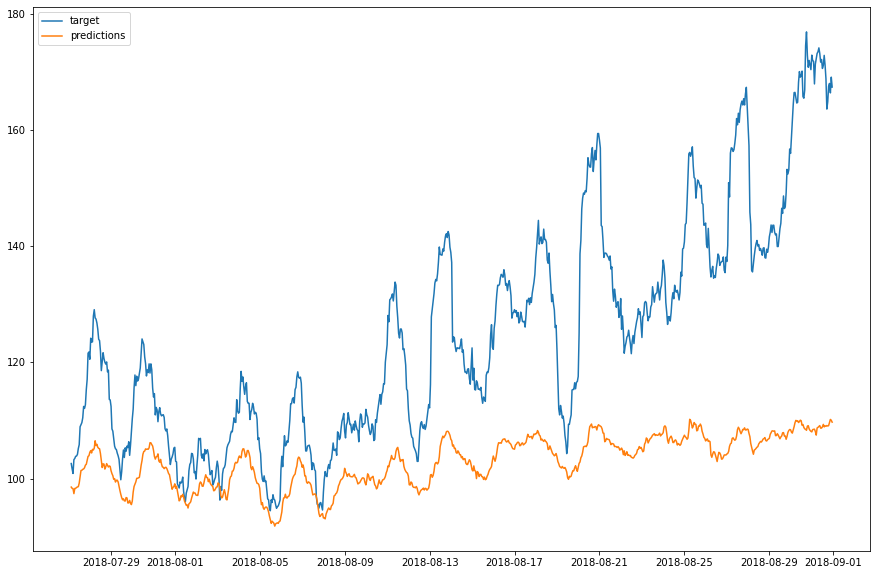

In [434]:
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(features_test.index, target_test.rolling(24).mean(), label='target')
ax.plot(features_test.index, LightGBM_predictions_df.rolling(24).mean(), label='predictions')
ax.legend();

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ РЕВЬЮЕРА 2</b></u></p>
ОК, Мария, увидел корректировки. Принято. Единственное - не увидел ответа - как подбирались гиперпараметры для омдели(( Может времени у тебя нет или заморачиваться не очень хочется)) Но это важно же. Если так сделать, то как и писсал, - слабая будет работа с позиции аргументированности нашего решения. Давай я оставлю код для ознакомления, как для временных рядов можно будет оформить поиск гиперпараметров - обязательно ознакомся!!!!<br>
    
А глядя на график (лучше и заголовок тоже оформлять !!!!! - порядок будет)), а также добавляя отдельный анализ остатков, можно будет хорошо порабоать над улучшением модели..<br>
Например, сейчас видно, что на тесте  прогноз систематически ниже факта. Это означает, что модель перестаёт работать как надо. Хотя метрика в норме.<br>
Причина? На рынке появился новый фактор продаж: цена, "умер" конкурент.... Из-за которого начал меняться тренд. А на трайне мы обучались без него. По хорошем, надо бы поработать ещё с моделью. Но это другая история)))<br>

Сейчас понятно, почему метрика в норме - тест выборка взята 20% (по заданию надо 10%) Но не буду из-за этого туда-сюда проект отсылать. Тут вот что главное учесть в таких работах: самые свежие данные - максимально влияют на прогноз на завтра. Вот если мы хотим преедсказать прогноз на завтра, то сегодняшние продажи будут наиболее информативными для этого. А ессли так: данные усекли на 20% и надо предсказть на завтра. Т.е. сегодня 29  мая, скажем, а прогноз надо сделать на 30, но истории продаж за весь май - нет(((( Рискуем "накосчить". Поэтому так: обучили, нашли лучшую модель. Но перед использованием - обязательно обучаем и на тест_данных. Потом уже прогноз на завтра. Так мы сможем улучшить качество.<br><br>

Тут много ещё что можно сказать по самой теме...<br>
Если будет возможность тебе однозначно интересно посмотреть разные практические истории вот здесь:<br>
https://ibf.org/knowledge - заморский институт бизнес-прогнозирования.<br>
Там и статьи можно накопать, и методы посмомтерть...<br>

Есть классический труд (он НЕ ML, а исключительно на эксель). Но для понимания сути временных рядов - то, что надо:<br>
УИЧЕРН "Бизнес-прогнозирование"<br>

Идеологически по системе прогнозирования, интересно почитать<br>
ТОМАС УОЛЛАС, Р. СТАЛЬ "планирование продаж и операций" SO&P<br><br>     

Спасибо за проект)<br>
УСПЕШНОГО ДАЛЬНЕЙШЕГО ОБЧЕНИЯ!</div>

## Чек-лист проверки

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Данные загружены и подготовлены
- [ ]  Данные проанализированы
- [ ]  Модель обучена, гиперпараметры подобраны
- [ ]  Качество моделей проверено, выводы сделаны
- [ ]  Значение *RMSE* на тестовой выборке не больше 48